# Comparison Between LinearRegression and KNN Models

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score)
from sklearn.utils.validation import check_is_fitted

In [2]:
X_test = pd.read_csv('data/X_test_pre.csv')
y_test = pd.read_csv('data/y_test.csv').squeeze('columns')

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (201, 9)
y_test shape: (201,)


In [3]:
linear_model = joblib.load('../models/LinearReg.pkl')
knn_model = joblib.load('../models/knn_regressor.pkl')

In [4]:
# This check prevents evaluation of an unfitted model.
check_is_fitted(linear_model)

try:
    check_is_fitted(knn_model)
except Exception as error:
    raise RuntimeError(
        "The saved KNN model is not fitted. "
        ) from error

print("Both models are fitted and ready for comparison.")

Both models are fitted and ready for comparison.


In [5]:
linear_pred = linear_model.predict(X_test)
knn_pred = knn_model.predict(X_test)

6. Compare Evaluation Metrics

- RMSE: lower is better.
- MAE: lower is better.
- R²: higher is better.

In [6]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regressor'],
    
    'RMSE': [
        root_mean_squared_error(y_test, linear_pred),
        root_mean_squared_error(y_test, knn_pred)],
    
    'MAE': [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, knn_pred)],
    
    'R2': [
        r2_score(y_test, linear_pred),
        r2_score(y_test, knn_pred)]
    
}).set_index('Model')

display(results.round(3))

,RMSE,MAE,R2
Model,,,
Linear Regression,6162.781,4041.915,0.777
KNN Regressor,5901.323,3481.535,0.796


Plotting Comparison

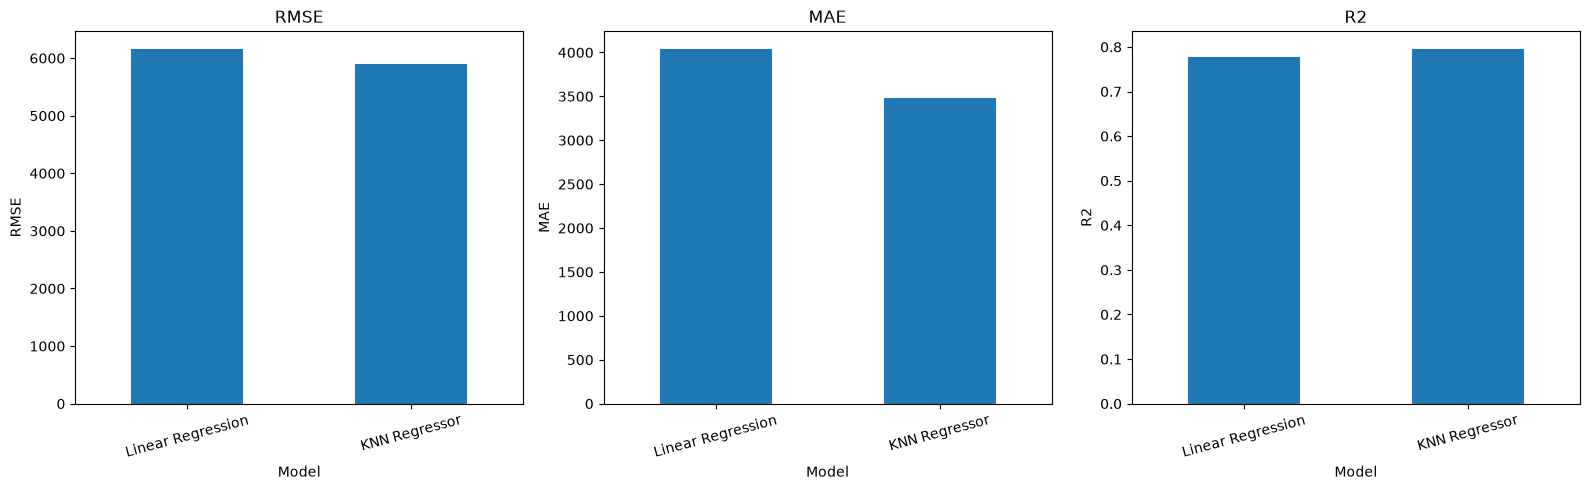

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ['RMSE', 'MAE', 'R2']):
    results[metric].plot(kind='bar', ax=ax)
    ax.set_title(metric)
    ax.set_xlabel('Model')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 8. Actual vs Predicted

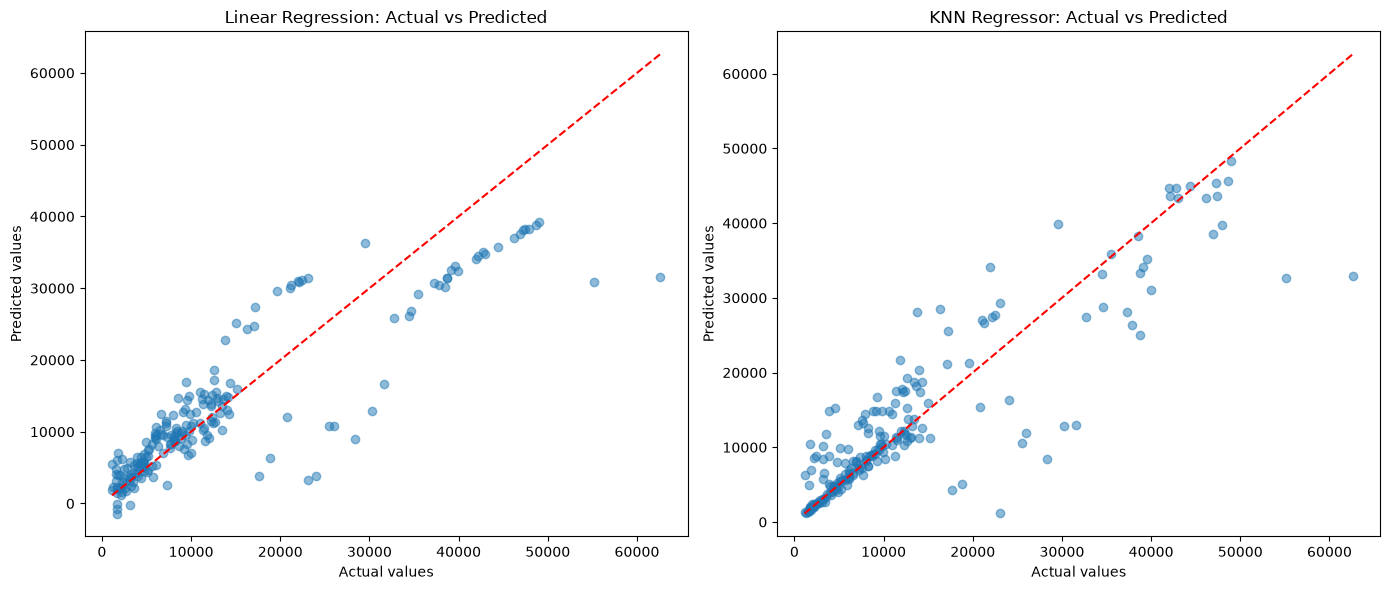

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

predictions = {
    'Linear Regression': linear_pred,
    'KNN Regressor': knn_pred}

for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.5)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--'
    )
    ax.set_xlabel('Actual values')
    ax.set_ylabel('Predicted values')
    ax.set_title(f'{name}: Actual vs Predicted')

plt.tight_layout()
plt.show()

## 9. Residual Comparison

Residual = Actual - Predicted. A residual distribution concentrated around zero is generally preferable.

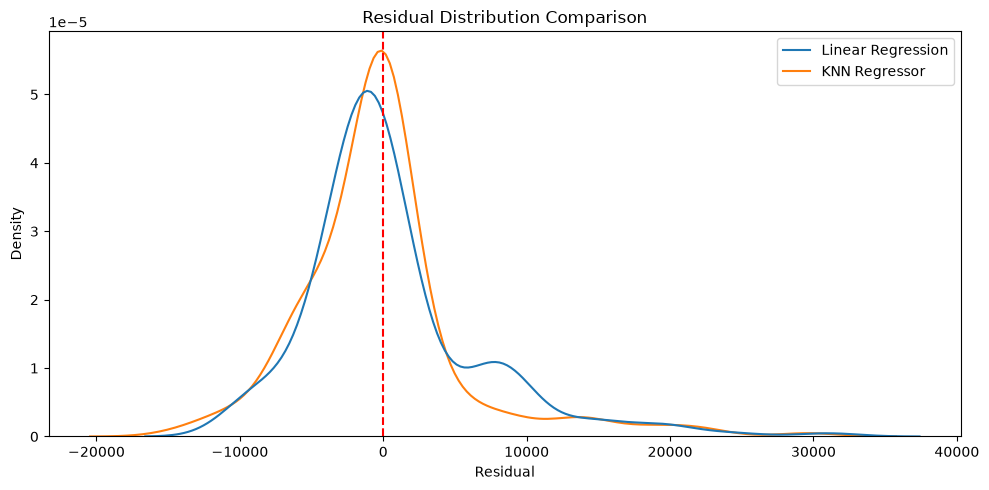

In [9]:
residuals = pd.DataFrame({
    'Linear Regression': y_test - linear_pred.ravel(),
    'KNN Regressor': y_test - knn_pred.ravel()
})

plt.figure(figsize=(10, 5))
sns.kdeplot(data=residuals, fill=False)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Residual')
plt.title('Residual Distribution Comparison')
plt.tight_layout()
plt.show()

## 10. Best Model

The model with the lowest test RMSE is selected by this comparison. MAE and R² are also considered.

In [10]:
best_model_name = results['RMSE'].idxmin()

print("Best model based on test RMSE:", best_model_name)
display(results.sort_values('RMSE').round(3))

Best model based on test RMSE: KNN Regressor


,RMSE,MAE,R2
Model,,,
KNN Regressor,5901.323,3481.535,0.796
Linear Regression,6162.781,4041.915,0.777
